# Same Question in Urdu, Roman Urdu, and English: Cross-Script LLM Evaluation

**Assignment Topic 6:** Evaluate LLM accuracy gaps when answering identical reading comprehension and idiom questions across **English (`eng_Latn`)**, **Urdu Nastaliq (`urd_Arab`)**, and **Roman Urdu (`urd_Latn`)**, and test whether **"Transliterate First, Then Answer" (TFTA)** closes the gap.

**Datasets:**
1. **Dakshina (Google)** — native Urdu & human-romanized parallel sentences + token alignments
2. **Roman-Urdu-Parl-split** — large-scale parallel Urdu / Roman-Urdu corpus
3. **Belebele** — 900 parallel reading comprehension questions (`urd_Arab` & `eng_Latn`)
4. **Urdu Idioms (`arXiv:2510.17460`)** — aligned idiom sentences in Nastaliq, Roman Urdu & English

In [1]:
# Cell 1: Imports, Paths & Environment Verification
import json, os, re, hashlib, random
from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein
from statsmodels.stats.contingency_tables import mcnemar
from IPython.display import display

ROOT = Path("..").resolve() if Path("..").resolve().joinpath("data").exists() else Path(".").resolve()
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
RES_DIR = ROOT / "data" / "results"
MODEL = "gemini-3.5-flash-lite"

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 65)

print(f"Project Root : {ROOT}")
print(f"Raw Datasets : {[p.name for p in sorted(RAW_DIR.iterdir())]}")
print(f"Result Files : {[p.name for p in sorted(RES_DIR.glob('*pilot*'))]}")

Project Root : /home/momin/D drive/shariq 3rd ai assignment
Raw Datasets : ['belebele', 'dakshina', 'roman_urdu_parl', 'urdu_idioms']
Result Files : ['analysis_summary_pilot_gemini-3.5-flash-lite.json', 'belebele_pilot_gemini-3.5-flash-lite.jsonl', 'idioms_equiv_pilot_gemini-3.5-flash-lite.jsonl', 'idioms_meaning_pilot_gemini-3.5-flash-lite.jsonl']


In [2]:
# Cell 2: Dataset Audit & Parallel Alignment Verification
def read_jsonl(path: Path):
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]

ur_raw = read_jsonl(RAW_DIR / "belebele" / "urd_Arab.jsonl")
en_raw = read_jsonl(RAW_DIR / "belebele" / "eng_Latn.jsonl")
ur_keys = {(r["link"], int(r["question_number"])): r for r in ur_raw}
en_keys = {(r["link"], int(r["question_number"])): r for r in en_raw}
matched = set(ur_keys) & set(en_keys)
same_ans = sum(str(ur_keys[k]["correct_answer_num"]) == str(en_keys[k]["correct_answer_num"]) for k in matched)

bele_3 = read_jsonl(PROC_DIR / "belebele_3scripts.jsonl")
idioms_3 = read_jsonl(PROC_DIR / "idioms_3scripts.jsonl")
dakshina_df = pd.read_parquet(RAW_DIR / "dakshina" / "ur.parquet")

audit_df = pd.DataFrame([
    {"Dataset": "Belebele (urd_Arab + eng_Latn)", "Raw Rows": len(ur_raw), "Clean Aligned": len(matched), "Notes": f"Answer match: {same_ans}/{len(matched)}; Pilot: {sum(r['is_pilot'] for r in bele_3)}"},
    {"Dataset": "Urdu Idioms (arXiv:2510.17460)", "Raw Rows": 2107, "Clean Aligned": 2002, "Notes": f"Removed 105 blank rows; {len(idioms_3)} unique idioms"},
    {"Dataset": "Dakshina Urdu (ur.parquet)", "Raw Rows": len(dakshina_df), "Clean Aligned": len(dakshina_df), "Notes": "Rows 0..7999 train lexicon; 8000..9758 held-out test"},
    {"Dataset": "Roman-Urdu-Parl-split", "Raw Rows": 204500, "Clean Aligned": 199521, "Notes": "200k train + 4.5k val; small_test_set (4.5k) held out"},
])
display(audit_df)

,Dataset,Raw Rows,Clean Aligned,Notes
0,Belebele (urd_Arab + eng_Latn),900,900,Answer match: 900/900; Pilot: 121
1,Urdu Idioms (arXiv:2510.17460),2107,2002,Removed 105 blank rows; 1919 unique idioms
2,Dakshina Urdu (ur.parquet),9759,9759,Rows 0..7999 train lexicon; 8000..9758 held-out test
3,Roman-Urdu-Parl-split,204500,199521,200k train + 4.5k val; small_test_set (4.5k) held out


In [3]:
# Cell 3: Step 1 — Urdu Normalization, Rule Fallback & Corpus Lexicon Transliteration
URDU_CHAR_RE = re.compile(r"[\u0600-\u06FF\u0750-\u077F\uFB50-\uFDFF\uFE70-\uFEFF]")
URDU_WORD_OR_OTHER_RE = re.compile(r"([\u0600-\u06FF\u0750-\u077F\uFB50-\uFDFF\uFE70-\uFEFF]+|[0-9]+|[A-Za-z]+|[^\s])")
CHAR_MAP = str.maketrans({"ك": "ک", "ي": "ی", "ى": "ی", "ة": "ہ", "ه": "ہ", "ۀ": "ہ", "أ": "ا", "إ": "ا", "ٱ": "ا", "۔": ".", "،": ",", "؟": "?", "؛": ";", "٪": "%", "“": '"', "”": '"', "‘": "'", "’": "'", "۰": "0", "۱": "1", "۲": "2", "۳": "3", "۴": "4", "۵": "5", "۶": "6", "۷": "7", "۸": "8", "۹": "9", "٠": "0", "١": "1", "٢": "2", "٣": "3", "٤": "4", "٥": "5", "٦": "6", "٧": "7", "٨": "8", "٩": "9", "\u200c": " "})
ASPIRATED = {"بھ": "bh", "پھ": "ph", "تھ": "th", "ٹھ": "th", "جھ": "jh", "چھ": "chh", "دھ": "dh", "ڈھ": "dh", "ڑھ": "rh", "کھ": "kh", "گھ": "gh", "لھ": "lh", "مھ": "mh", "نھ": "nh"}
CONSONANTS = {"ب": "b", "پ": "p", "ت": "t", "ٹ": "t", "ث": "s", "ج": "j", "چ": "ch", "ح": "h", "خ": "kh", "د": "d", "ڈ": "d", "ذ": "z", "ر": "r", "ڑ": "r", "ز": "z", "ژ": "zh", "س": "s", "ش": "sh", "ص": "s", "ض": "z", "ط": "t", "ظ": "z", "غ": "gh", "ف": "f", "ق": "q", "ک": "k", "گ": "g", "ل": "l", "م": "m", "ن": "n", "ں": "n", "ھ": "h", "ء": ""}
DIACRITIC_VOWELS = {"\u064e": "a", "\u0650": "i", "\u064f": "u", "\u064b": "an", "\u064d": "in", "\u064c": "un", "\u0670": "a"}

def normalize_urdu(text: str) -> str:
    text = re.sub(r"[\u200e\u200f\u202a-\u202e\u2066-\u2069\u0640]", "", text).translate(CHAR_MAP)
    return re.sub(r"\s+", " ", re.sub(r"(\d)ء", r"\1", text)).strip()

@lru_cache(maxsize=65536)
def rule_transliterate_word(word: str) -> str:
    clean = normalize_urdu(word)
    if not clean or not URDU_CHAR_RE.search(clean):
        return clean
    out, i, n = [], 0, len(clean)
    while i < n:
        ch, nxt = clean[i], (clean[i + 1] if i + 1 < n else "")
        prev = clean[i - 1] if i > 0 else ""
        if ch in DIACRITIC_VOWELS: out.append(DIACRITIC_VOWELS[ch]); i += 1; continue
        if ch == "\u0651":
            if out and out[-1] and out[-1][-1].isalpha(): out.append(out[-1][-1])
            i += 1; continue
        if ch in ("\u0652", "\u0654", "\u0655"): i += 1; continue
        if nxt == "ھ" and (ch + nxt) in ASPIRATED:
            out.append(ASPIRATED[ch + nxt]); i += 2; continue
        if ch == "آ": out.append("aa")
        elif ch == "ا":
            if i == 0 and nxt == "و": out.append("o"); i += 2; continue
            if i == 0 and nxt == "ی": out.append("ai"); i += 2; continue
            out.append("a" if (i == 0 or i == n - 1 or prev not in CONSONANTS) else "aa")
        elif ch == "ع": out.append("a")
        elif ch == "و": out.append("w" if i == 0 else ("o" if (i == n - 1 or prev not in CONSONANTS) else "oo"))
        elif ch == "ؤ": out.append("o")
        elif ch in ("ی", "ئ"): out.append("y" if i == 0 else ("i" if i == n - 1 else ("ee" if nxt in CONSONANTS else "i")))
        elif ch == "ے": out.append("ay" if i == n - 1 else "e")
        elif ch == "ہ": out.append("a" if (i == n - 1 and prev in CONSONANTS) else "h")
        else: out.append(CONSONANTS.get(ch, ch))
        i += 1
    return re.sub(r"([a-z])\1{2,}", r"\1\1", "".join(out))

lexicon = json.loads((PROC_DIR / "roman_lexicon.json").read_text(encoding="utf-8"))
print(f"Loaded Dakshina + Phonetically Filtered Parl Lexicon: {len(lexicon):,} entries")

def corpus_rule_transliterate(text: str, lex: dict):
    norm = normalize_urdu(text)
    if not norm:
        return "", 0, 0
    parts, total_u, hits = [], 0, 0
    for tok in URDU_WORD_OR_OTHER_RE.findall(norm):
        if URDU_CHAR_RE.search(tok):
            total_u += 1
            key = re.sub(r"[\u064B-\u065F\u0670]", "", tok)
            if key in lex:
                hits += 1; parts.append(lex[key])
            else:
                parts.append(rule_transliterate_word(tok))
        else:
            parts.append(tok)
    joined = re.sub(r"\s+([.,?;:!%)\]}])", r"\1", " ".join(parts))
    joined = re.sub(r"([(\[{])\s+", r"\1", joined)
    joined = re.sub(r"\s+'s\b", "'s", joined)
    joined = re.sub(r"\s+", " ", joined).strip()
    return joined, hits, total_u

def score_heldout(pairs):
    tot_edit = tot_chars = tot_hits = tot_toks = 0
    sims = []
    for nat, gold in pairs:
        pred, hits, n_u = corpus_rule_transliterate(nat, lexicon)
        p, g = re.sub(r"\s+", " ", pred.lower().strip()), re.sub(r"\s+", " ", gold.lower().strip())
        d = Levenshtein.distance(p, g)
        tot_edit += d; tot_chars += max(len(g), 1)
        sims.append(1.0 - d / max(len(p), len(g), 1))
        tot_hits += hits; tot_toks += n_u
    return {"n_sentences": len(pairs), "cer": round(tot_edit / max(tot_chars, 1), 4), "char_similarity": round(sum(sims) / len(sims), 4), "lexicon_coverage": round(tot_hits / max(tot_toks, 1), 4)}

import csv
parl_rows = list(csv.reader((RAW_DIR / "roman_urdu_parl" / "small_test_set.csv").open(encoding="utf-8")))[1:]
translit_eval = {
    "dakshina_heldout_test": score_heldout(list(zip(dakshina_df.iloc[8000:]["native"].astype(str), dakshina_df.iloc[8000:]["romanized"].astype(str)))),
    "roman_urdu_parl_small_test": score_heldout([(r[0], r[1]) for r in parl_rows if len(r) >= 2 and r[0].strip() and r[1].strip()]),
}
display(pd.DataFrame(translit_eval).T)

Loaded Dakshina + Phonetically Filtered Parl Lexicon: 27,815 entries


,n_sentences,cer,char_similarity,lexicon_coverage
dakshina_heldout_test,1759.0,0.1065,0.8887,0.9659
roman_urdu_parl_small_test,4500.0,0.1523,0.8481,0.9875


In [4]:
# Cell 4: Hybrid Roman Urdu & 3-Script Benchmark Inspection
sample_b = [r for r in bele_3 if r["transliteration_source"] == "hybrid_gemini"][:3]
rows_preview = []
for r in sample_b:
    rows_preview.append({
        "Item ID": r["item_id"],
        "English (eng_Latn)": r["eng_Latn"]["question"],
        "Urdu Nastaliq (urd_Arab)": r["urd_Arab"]["question"],
        "Roman Corpus-Rule": r["urd_Latn_corpus"]["question"],
        "Roman Hybrid": r["urd_Latn"]["question"],
    })
display(pd.DataFrame(rows_preview))

sample_i = idioms_3[0]
print("Sample Idiom (3-Script Figurative Meaning QA):")
print("  Urdu Nastaliq :", sample_i["urdu_sentence"])
print("  Roman Urdu    :", sample_i["roman_sentence"])
print("  English       :", sample_i["english_sentence"])
print("  Target Meaning:", sample_i["meaning_options"][sample_i["meaning_correct_num"] - 1])

,Item ID,English (eng_Latn),Urdu Nastaliq (urd_Arab),Roman Corpus-Rule,Roman Hybrid
0,belebele_0007,Where were Colonel Stark’s troops situated?,کرنل اسٹارک کے فوجی کہاں موجود تھے؟,Colonel astaark ke fauji kahan maujood the?,Colonel Stark ke fauji kahan maujood the?
1,belebele_0008,"According to the passage, when did Stark’s men extend their f...",اقتباس کے مطابق، اسٹارک کے آدمیوں نے اپنی باڑ کب بڑھائی؟,"Iqtabas ke mutaabiq, astaark ke aadmiyon ne apni baar kab bad...","Iqtabas ke mutabiq, Stark ke aadmiyon ne apni baar kab barhai?"
2,belebele_0012,Which of the following will continue despite the presence of ...,فطرت پر مبنی سیاحتی سرگرمی کی مثال مندرجہ ذیل میں کون سی نہیں...,Fitrat par mabni syaahati sargarmi ki misaal mandarja zail me...,Fitrat par mabni sayahati sargarmi ki misaal mandarja zail me...


Sample Idiom (3-Script Figurative Meaning QA):
  Urdu Nastaliq : اس نے سب کو آنکھوں میں دھول جھونک کر اپنا کام نکالا،
  Roman Urdu    : Us ne sab ko aankhon mein dhool jhonk kar apna kaam nikala
  English       : He pulled the wool over everyone’s eyes to get his work done.
  Target Meaning: Deceive a person by hiding the truth to make them believe a lie


In [5]:
# Cell 5: Steps 2-4 — Prompt Templates, Answer Parser & Cache-Backed Gemini Evaluation
LETTERS = ["A", "B", "C", "D"]

def parse_mc_answer(text: str):
    cleaned = re.sub(r"^```(?:json)?\s*|\s*```$", "", (text or "").strip(), flags=re.I | re.S).strip()
    try:
        obj = json.loads(cleaned)
        if isinstance(obj, dict):
            ans = str(obj.get("answer", "")).strip().upper()
            if ans in LETTERS: return ans
            if ans in {"1", "2", "3", "4"}: return LETTERS[int(ans) - 1]
    except json.JSONDecodeError:
        pass
    m = re.search(r'(?i)"answer"\s*:\s*"([A-D1-4])"', cleaned)
    if m:
        ch = m.group(1).upper()
        return LETTERS[int(ch) - 1] if ch.isdigit() else ch
    return None

def format_belebele_prompt(fields: dict) -> str:
    return (
        "Read the following passage carefully and choose the single best answer (A, B, C, or D).\n"
        'Respond ONLY with valid JSON: {"answer": "A"|"B"|"C"|"D"}.\n\n'
        f"Passage:\n{fields['flores_passage']}\n\nQuestion:\n{fields['question']}\n\n"
        f"A) {fields['mc_answer1']}\nB) {fields['mc_answer2']}\nC) {fields['mc_answer3']}\nD) {fields['mc_answer4']}"
    )

def format_tfta_prompt(fields: dict) -> str:
    return (
        "The following reading comprehension item is written in Roman Urdu (Urdu written in Latin script).\n"
        "Follow these two steps strictly:\n"
        "1. First transliterate the Roman Urdu passage, question, and all four options into native Urdu script (Perso-Arabic / Nastaliq).\n"
        "2. Then read your Urdu transliteration and choose the single best answer (A, B, C, or D).\n\n"
        'Respond ONLY with valid JSON: {"urdu_transliteration": "<passage and question in Urdu script>", "answer": "A"|"B"|"C"|"D"}.\n\n'
        f"Passage:\n{fields['flores_passage']}\n\nQuestion:\n{fields['question']}\n\n"
        f"A) {fields['mc_answer1']}\nB) {fields['mc_answer2']}\nC) {fields['mc_answer3']}\nD) {fields['mc_answer4']}"
    )

# Verify deterministic cache replay on the 45 Belebele + 30 Idioms-Meaning + 40 Idioms-Equiv runs
bele_res = pd.DataFrame(read_jsonl(RES_DIR / f"belebele_pilot_{MODEL}.jsonl"))
meaning_res = pd.DataFrame(read_jsonl(RES_DIR / f"idioms_meaning_pilot_{MODEL}.jsonl"))
equiv_res = pd.DataFrame(read_jsonl(RES_DIR / f"idioms_equiv_pilot_{MODEL}.jsonl"))
print(f"Loaded evaluated records -> Belebele: {len(bele_res)} | Idioms-Meaning: {len(meaning_res)} | Idioms-Equiv: {len(equiv_res)}")
print(f"Overall JSON Answer Parse Rate: {pd.concat([bele_res, meaning_res, equiv_res])['parse_ok'].mean()*100:.1f}%")

Loaded evaluated records -> Belebele: 225 | Idioms-Meaning: 120 | Idioms-Equiv: 120
Overall JSON Answer Parse Rate: 100.0%


In [6]:
# Cell 6: Statistical Evaluation — Accuracy, 95% Bootstrap CIs & Paired McNemar Tests
def bootstrap_ci(arr, n_boot=5000, seed=42):
    arr = np.asarray(arr, dtype=float)
    rng = np.random.default_rng(seed)
    boots = arr[rng.integers(0, len(arr), size=(n_boot, len(arr)))].mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return float(arr.mean()), float(lo), float(hi)

def summarize(df, name):
    rows = []
    for cond, grp in df.groupby("condition", sort=False):
        m, lo, hi = bootstrap_ci(grp["correct"].to_numpy())
        rows.append({
            "Benchmark": name, "Condition": cond, "N": len(grp),
            "Accuracy (%)": round(m * 100, 2),
            "95% CI": f"[{lo*100:.1f}, {hi*100:.1f}]",
            "Avg Out Tokens": round(grp["output_tokens"].mean(), 1),
            "Avg Latency (s)": round(grp["latency_s"].mean(), 2),
        })
    return pd.DataFrame(rows)

summary_all = pd.concat([
    summarize(bele_res, "Belebele RC"),
    summarize(meaning_res, "Idioms Meaning"),
    summarize(equiv_res, "Idioms Raw Equiv"),
], ignore_index=True)
display(summary_all)

# Exact paired McNemar comparisons
summary_json = json.loads((RES_DIR / f"analysis_summary_pilot_{MODEL}.json").read_text(encoding="utf-8"))
mcn_rows = []
for bname, bdata in summary_json["benchmarks"].items():
    for c in bdata["mcnemar_comparisons"]:
        mcn_rows.append({"Benchmark": bname, "Pair": f"{c['condition_a']} -> {c['condition_b']}", "N": c["n"], "Gap (pp)": c["diff_pp"], "A-only": c["a_only_correct"], "B-only": c["b_only_correct"], "p-value": round(c["p_value"], 5)})
display(pd.DataFrame(mcn_rows))

,Benchmark,Condition,N,Accuracy (%),95% CI,Avg Out Tokens,Avg Latency (s)
0,Belebele RC,eng_Latn,45,100.00,"[100.0, 100.0]",6.8,1.36
1,Belebele RC,urd_Arab,45,86.67,"[75.6, 95.6]",6.4,2.19
2,Belebele RC,urd_Latn_corpus,45,86.67,"[75.6, 95.6]",7.0,1.41
3,Belebele RC,urd_Latn_hybrid,45,84.44,"[73.3, 93.3]",7.1,0.95
4,Belebele RC,urd_Latn_tfta_single,45,88.89,"[80.0, 97.8]",248.8,1.87
5,Idioms Meaning,eng_Latn,30,100.00,"[100.0, 100.0]",6.8,7.09
6,Idioms Meaning,urd_Arab,30,100.00,"[100.0, 100.0]",6.5,9.22
7,Idioms Meaning,urd_Latn,30,96.67,"[90.0, 100.0]",6.7,9.01
8,Idioms Meaning,urd_Latn_tfta,30,96.67,"[90.0, 100.0]",51.0,8.38
9,Idioms Raw Equiv,urd_Arab,40,97.50,"[92.5, 100.0]",6.6,3.05


,Benchmark,Pair,N,Gap (pp),A-only,B-only,p-value
0,Belebele Reading Comprehension,eng_Latn -> urd_Arab,45,-13.33,6,0,0.03125
1,Belebele Reading Comprehension,urd_Arab -> urd_Latn_corpus,45,0.00,1,1,1.00000
2,Belebele Reading Comprehension,urd_Arab -> urd_Latn_hybrid,45,-2.22,2,1,1.00000
3,Belebele Reading Comprehension,urd_Latn_corpus -> urd_Latn_hybrid,45,-2.22,1,0,1.00000
4,Belebele Reading Comprehension,urd_Latn_corpus -> urd_Latn_tfta_single,45,2.22,1,2,1.00000
5,Belebele Reading Comprehension,urd_Latn_hybrid -> urd_Latn_tfta_single,45,4.44,1,3,0.62500
6,Urdu Idioms (3-Script Meaning),eng_Latn -> urd_Arab,30,0.00,0,0,1.00000
7,Urdu Idioms (3-Script Meaning),urd_Arab -> urd_Latn,30,-3.33,1,0,1.00000
8,Urdu Idioms (3-Script Meaning),urd_Latn -> urd_Latn_tfta,30,0.00,0,0,1.00000
9,Urdu Idioms (3-Script Meaning),urd_Arab -> urd_Latn_tfta,30,-3.33,1,0,1.00000


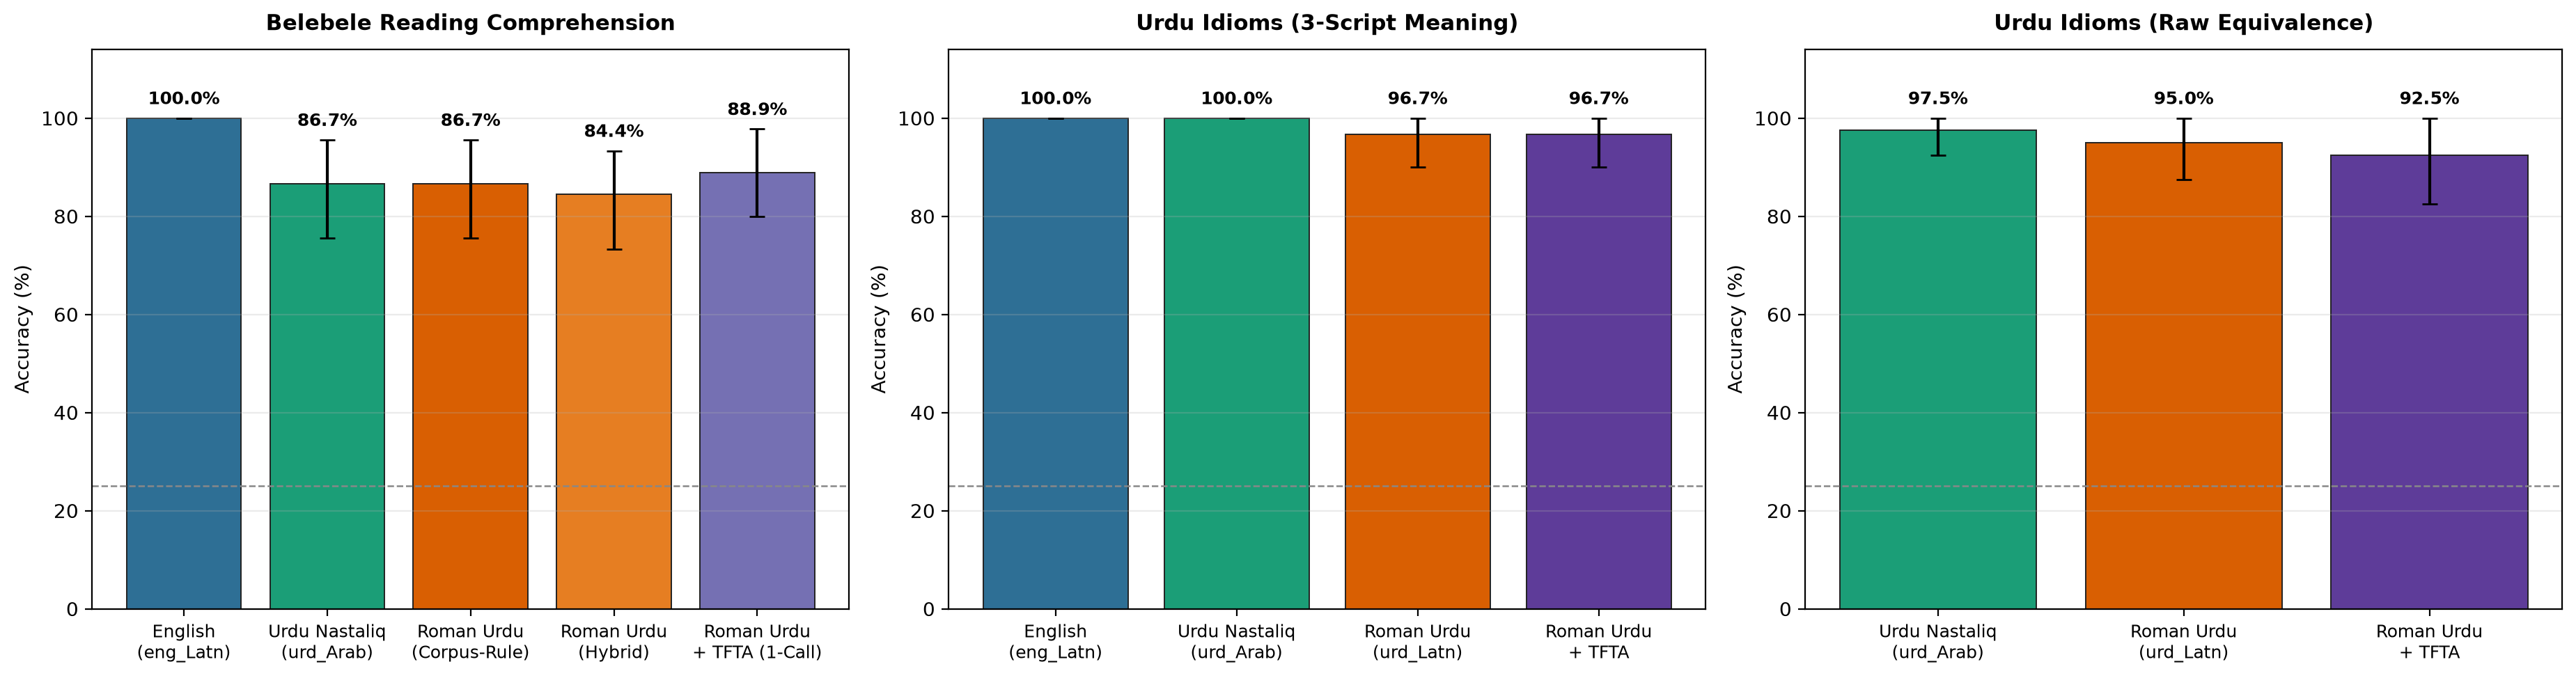

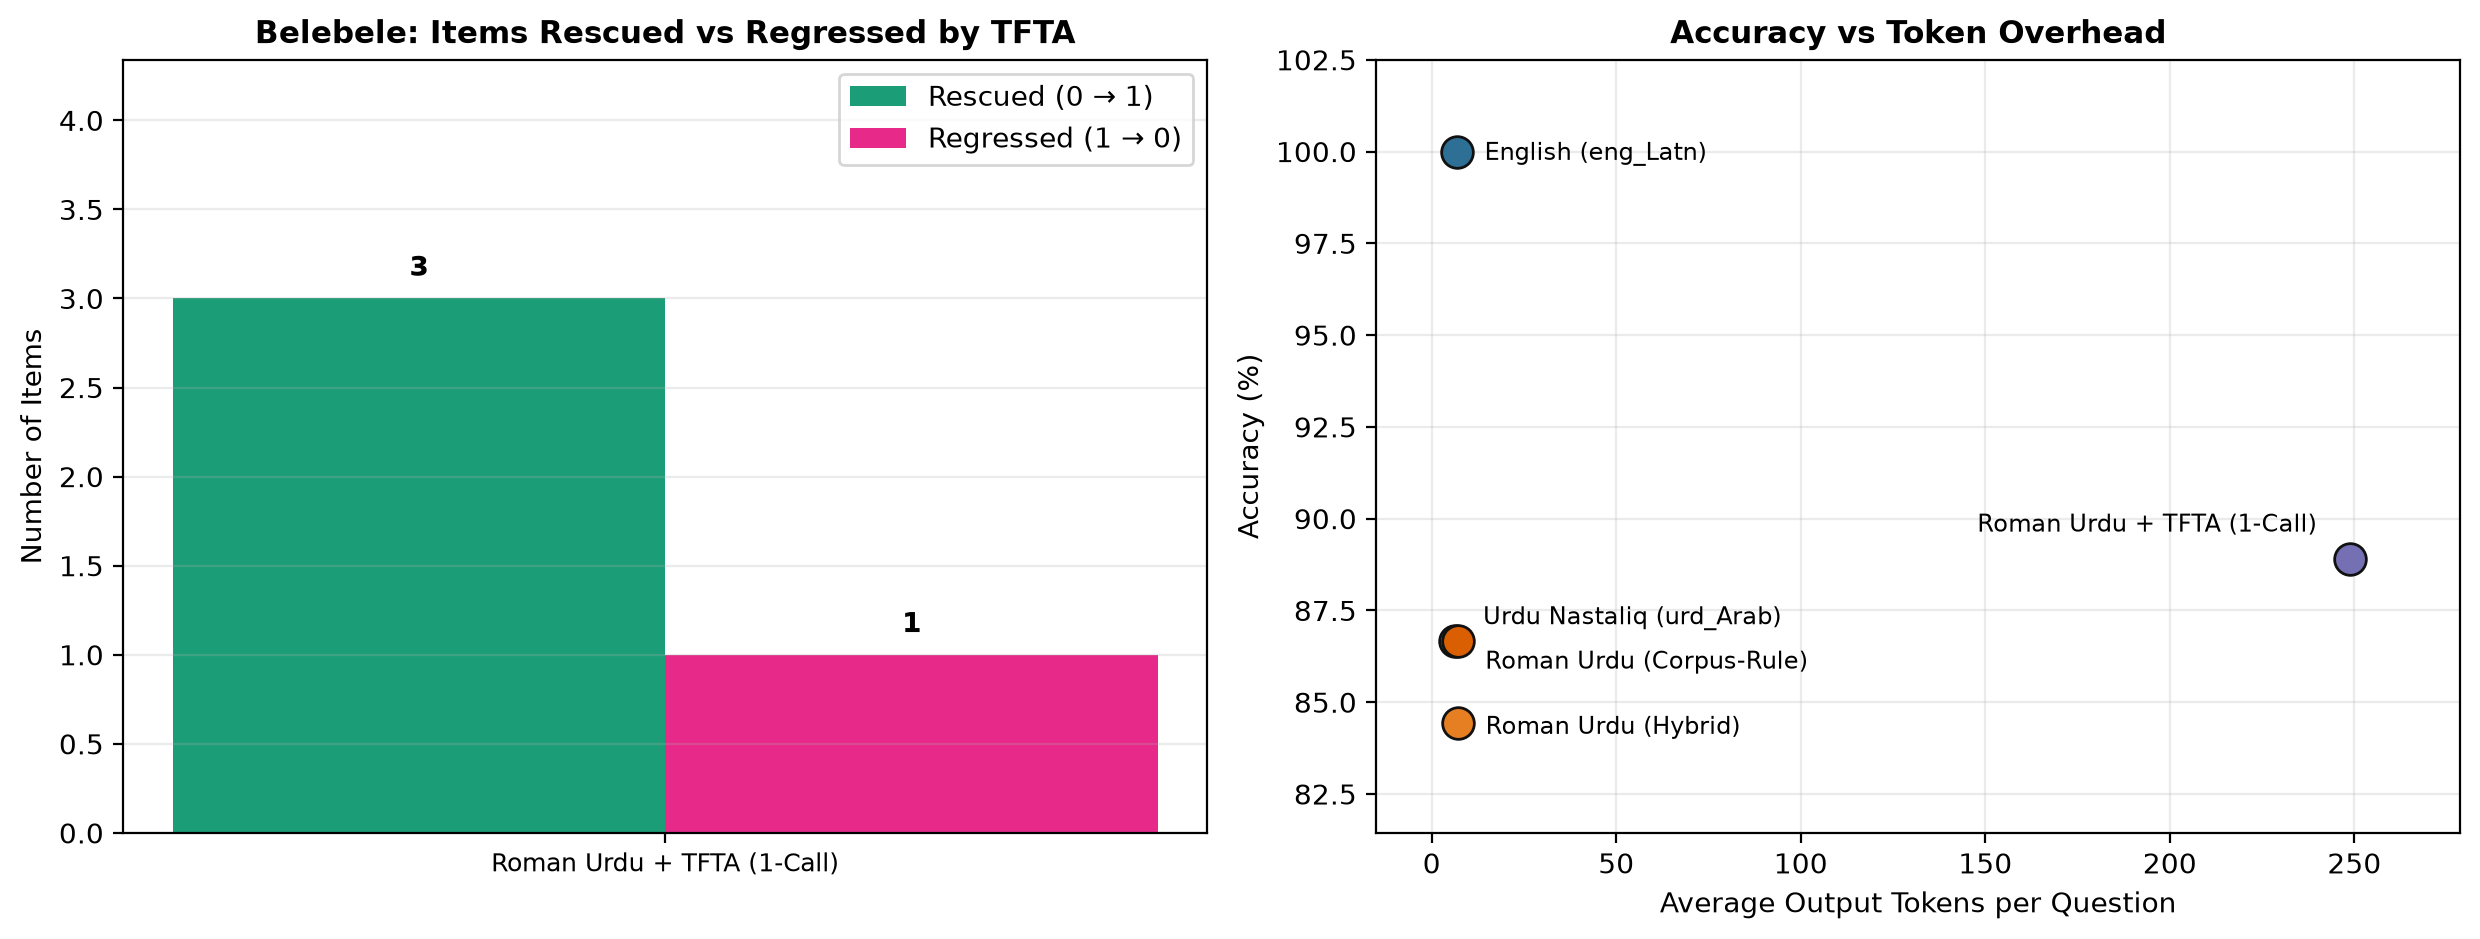

In [7]:
# Cell 7: Visualization — Cross-Script Accuracy & TFTA Flip/Token Trade-offs
from IPython.display import Image
display(Image(filename=str(RES_DIR / "figures" / f"accuracy_comparison_pilot_{MODEL}.png")))
display(Image(filename=str(RES_DIR / "figures" / f"tfta_flips_overhead_pilot_{MODEL}.png")))

In [8]:
# Cell 8: Slice Error Analysis, TFTA Rescues & Upstream Benchmark Audit
piv = bele_res.pivot(index="item_id", columns="condition", values="correct")
rescued = piv[(piv["urd_Latn_hybrid"] == 0) & (piv["urd_Latn_tfta_single"] == 1)].index.tolist()
regressed = piv[(piv["urd_Latn_hybrid"] == 1) & (piv["urd_Latn_tfta_single"] == 0)].index.tolist()
print(f"TFTA Rescued (0->1): {rescued}")
print(f"TFTA Regressed (1->0): {regressed}")
print("Back-transliteration fidelity (TFTA vs gold urd_Arab):", summary_json.get("backtransliteration_fidelity", {}))

bele_map = {r["item_id"]: r for r in bele_3}
idiom_map = {r["item_id"]: r for r in idioms_3}
print("\n--- Example TFTA Rescue (belebele_0008) ---")
print("  Urdu Q   :", bele_map["belebele_0008"]["urd_Arab"]["question"])
print("  Roman Q  :", bele_map["belebele_0008"]["urd_Latn"]["question"])

print("\n--- Upstream Dataset Anomalies Discovered ---")
print("  [belebele_0012] EN Q:", bele_map["belebele_0012"]["eng_Latn"]["question"])
print("                  UR Q:", bele_map["belebele_0012"]["urd_Arab"]["question"])
print("  [belebele_0278] EN Q:", bele_map["belebele_0278"]["eng_Latn"]["question"])
print("                  UR Q:", bele_map["belebele_0278"]["urd_Arab"]["question"])
print("  [idiom_0020]    UR  :", idiom_map["idiom_0020"]["urdu_sentence"])
print("                  RU  :", idiom_map["idiom_0020"]["roman_sentence"], "| EN label:", idiom_map["idiom_0020"]["english_idiom"])

TFTA Rescued (0->1): ['belebele_0008', 'belebele_0153', 'belebele_0170']
TFTA Regressed (1->0): ['belebele_0007']
Back-transliteration fidelity (TFTA vs gold urd_Arab): {'urd_Latn_tfta_single': {'n_scored': 44, 'mean_char_sim_all': 0.9427, 'mean_char_sim_correct': 0.9421, 'mean_char_sim_wrong': 0.9479}}

--- Example TFTA Rescue (belebele_0008) ---
  Urdu Q   : اقتباس کے مطابق، اسٹارک کے آدمیوں نے اپنی باڑ کب بڑھائی؟
  Roman Q  : Iqtabas ke mutabiq, Stark ke aadmiyon ne apni baar kab barhai?

--- Upstream Dataset Anomalies Discovered ---
  [belebele_0012] EN Q: Which of the following will continue despite the presence of external cues?
                  UR Q: فطرت پر مبنی سیاحتی سرگرمی کی مثال مندرجہ ذیل میں کون سی نہیں ہوگی؟
  [belebele_0278] EN Q: What was the second-last performance of the evening?
                  UR Q: شام کی دوسری اور آخری پرفارمنس کیا تھی؟
  [idiom_0020]    UR  : ان دونوں کی شادی پر کہا گیا کہاں راجہ بھوج کہاں گنگوتیلی۔
                  RU  : Woh aakhirkar aaya

## Summary & Conclusions
1. **Cross-Script Gap:** On Belebele Reading Comprehension (`N=45`), switching from English (`100.0%`) to Urdu Nastaliq (`86.67%`) caused a statistically significant **-13.33 pp** accuracy drop (`p = 0.03125`), while switching from Nastaliq to Roman Urdu yielded `0.00 pp` (corpus-rule `86.67%`) to `-2.22 pp` (hybrid `84.44%`). On Urdu Idioms (`N=30` & `N=40`), Roman Urdu achieved `96.67%` and `95.00%` respectively.
2. **Effect of TFTA:** On Belebele (`N=45`), "Transliterate First, Then Answer" improved Roman Urdu accuracy from `84.44%` to **`88.89%`** (`+4.44 pp`, rescuing 3 items vs. 1 regression; `0.9427` back-transliteration char similarity), at **35×** higher output token cost (`248.8` vs `7.1` tokens). On Idioms, TFTA yielded `0.00 pp` (`96.67%`) and `-2.50 pp` (`92.50%`) with `7.6×–9.6×` token overhead.